# Notebook 01: Multi-Source Data Ingestion & Web Crawling Pipeline (Module Ingestion)
> **Mục tiêu đồ án TradeToiChet**:
> 1. Thu thập dữ liệu Giá OHLCV 30 mã VN30 và chỉ số VN-Index (2019 - 2026).
> 2. Xây dựng dữ liệu Vĩ mô & Thị trường (Lãi suất tái cấp vốn SBV, Tỷ giá USD/VND, Biến động VN-Index).
> 3. Cào dữ liệu Tin tức doanh nghiệp từ CafeF bằng Web Scraper chống chặn IP (Anti-ban crawler).
> 4. Mô hình Học máy Chưng cất (Distilled Sentiment Model) chấm điểm cảm xúc tin tức tài chính tiếng Việt.
> 5. Kiểm tra schema, kiểu dữ liệu, missing values và tiêu chuẩn bàn giao dữ liệu thô (Data Contracts).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Thiet lap project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DATA_RAW_DIR, SQLITE_DB_PATH, VN30_TICKERS
from src.ingestion.price_fetcher import sync_all_prices
from src.ingestion.macro_builder import build_macro_dataset
from src.ingestion.news_crawler import sync_all_news
from src.ingestion.sentiment import score_vietnamese_headline
from src.ingestion.db import get_connection

print('Moi truong san sang. Thu muc du lieu thuc te:', DATA_RAW_DIR)

Moi truong san sang. Thu muc du lieu thuc te: /home/kibito/Desktop/repos/TradeToiChet/data/raw


## 1. Dữ liệu Giá Lịch sử OHLCV (30 mã VN30 & Chỉ số VN-Index)
- **Nguồn**: API biểu đồ kỹ thuật Entrade/DNSE (`services.entrade.com.vn`).
- **Cơ chế**: Tải dữ liệu nến ngày từ 01/01/2019 đến 01/03/2026. Tự động lưu cache SQLite (`bảng prices`), nếu đã có dữ liệu thì nạp trực tiếp tức thì từ SQLite không tốn request mạng.
- **Xử lý missing / điền khuyết**: Kiểm tra null trên từng cột giá và khối lượng; chuẩn hóa timezone về naive UTC datetime; lọc trùng lặp `(date, ticker)`.

In [2]:
# 1. Chay sync du lieu gia (Hit cache SQLite tuc thi neu da nap san)
df_prices = sync_all_prices(output_dir=DATA_RAW_DIR, db_path=SQLITE_DB_PATH)

# 2. Kiem tra schema, kieu du lieu va missing values
print('--- THONG TIN SCHEMA & KIEU DU LIEU (PRICES) ---')
df_prices.info()

print('\n--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---')
print(df_prices.isnull().sum())

print(f'\nTong so ma co phieu: {df_prices["ticker"].nunique()} | Khoang thoi gian: {df_prices["date"].min().date()} den {df_prices["date"].max().date()}')
df_prices.head(5)

[01/31] Cache hit in SQLite for ACB, skipping API call.
[02/31] Cache hit in SQLite for BCM, skipping API call.
[03/31] Cache hit in SQLite for BID, skipping API call.
[04/31] Cache hit in SQLite for BVH, skipping API call.
[05/31] Cache hit in SQLite for CTG, skipping API call.
[06/31] Cache hit in SQLite for FPT, skipping API call.
[07/31] Cache hit in SQLite for GAS, skipping API call.


[08/31] Cache hit in SQLite for GVR, skipping API call.
[09/31] Cache hit in SQLite for HDB, skipping API call.
[10/31] Cache hit in SQLite for HPG, skipping API call.
[11/31] Cache hit in SQLite for MBB, skipping API call.
[12/31] Cache hit in SQLite for MSN, skipping API call.
[13/31] Cache hit in SQLite for MWG, skipping API call.
[14/31] Cache hit in SQLite for PLX, skipping API call.
[15/31] Cache hit in SQLite for POW, skipping API call.
[16/31] Cache hit in SQLite for SAB, skipping API call.
[17/31] Cache hit in SQLite for SHB, skipping API call.


[18/31] Cache hit in SQLite for SSB, skipping API call.
[19/31] Cache hit in SQLite for SSI, skipping API call.
[20/31] Cache hit in SQLite for STB, skipping API call.
[21/31] Cache hit in SQLite for TCB, skipping API call.
[22/31] Cache hit in SQLite for TPB, skipping API call.
[23/31] Cache hit in SQLite for VCB, skipping API call.
[24/31] Cache hit in SQLite for VHM, skipping API call.
[25/31] Cache hit in SQLite for VIB, skipping API call.
[26/31] Cache hit in SQLite for VIC, skipping API call.


[27/31] Cache hit in SQLite for VJC, skipping API call.
[28/31] Cache hit in SQLite for VNM, skipping API call.
[29/31] Cache hit in SQLite for VPB, skipping API call.
[30/31] Cache hit in SQLite for VRE, skipping API call.
[31/31] Cache hit in SQLite for VNINDEX, skipping API call.


[OK] Saved 54,681 rows (31 tickers) to /home/kibito/Desktop/repos/TradeToiChet/data/raw/prices.parquet
--- THONG TIN SCHEMA & KIEU DU LIEU (PRICES) ---
<class 'pandas.DataFrame'>
RangeIndex: 54681 entries, 0 to 54680
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    54681 non-null  datetime64[us]
 1   ticker  54681 non-null  str           
 2   open    54681 non-null  float64       
 3   high    54681 non-null  float64       
 4   low     54681 non-null  float64       
 5   close   54681 non-null  float64       
 6   volume  54681 non-null  float64       
 7   sector  54681 non-null  str           
dtypes: datetime64[us](1), float64(5), str(2)
memory usage: 3.9 MB

--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---
date      0
ticker    0
open      0
high      0
low       0
close     0
volume    0
sector    0
dtype: int64

Tong so ma co phieu: 31 | Khoang thoi gian: 2019-01-02 den 2026-02-27


,date,ticker,open,high,low,close,volume,sector
0,2019-01-02,ACB,5.66,5.66,5.53,5.58,1103106.0,Banking
1,2019-01-03,ACB,5.02,5.57,5.02,5.38,1956382.0,Banking
2,2019-01-04,ACB,5.35,5.45,5.27,5.41,2771983.0,Banking
3,2019-01-07,ACB,5.53,5.53,5.45,5.49,1305819.0,Banking
4,2019-01-08,ACB,6.00,6.00,5.45,5.45,846226.0,Banking


## 2. Dữ liệu Vĩ mô & Thị trường (Macro Features)
- **Nguồn**:
  1. Suất sinh lời ngày và độ biến động 20 phiên tính từ chuỗi giá đóng cửa của chỉ số VN-Index (`vnindex_return_1d`, `vnindex_volatility_20d`).
  2. Lãi suất tái cấp vốn điều hành của Ngân hàng Nhà nước Việt Nam (`sbv_policy_rate`).
  3. Tỷ giá quy chuẩn USD/VND theo từng chu kỳ năm (`usd_vnd_rate`).
- **Xử lý missing / điền khuyết**: Phiên đầu tiên chưa có lợi nhuận ngày hôm trước được fill `0.0`. Độ biến động 20 phiên đầu tiên chưa đủ window 20 ngày được fill `0.0`.

In [3]:
# 1. Xay dung bang vi mo tu df_prices
df_macro = build_macro_dataset(df_prices=df_prices, output_dir=DATA_RAW_DIR, db_path=SQLITE_DB_PATH)

# 2. Kiem tra schema va mau du lieu
print('--- THONG TIN SCHEMA & KIEU DU LIEU (MACRO) ---')
df_macro.info()

print('\n--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---')
print(df_macro.isnull().sum())

df_macro.head(5)

[OK] Saved 1,751 rows of macro indicators to /home/kibito/Desktop/repos/TradeToiChet/data/raw/macro.parquet
--- THONG TIN SCHEMA & KIEU DU LIEU (MACRO) ---
<class 'pandas.DataFrame'>
RangeIndex: 1751 entries, 0 to 1750
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   date                    1751 non-null   datetime64[us]
 1   vnindex_close           1751 non-null   float64       
 2   vnindex_return_1d       1751 non-null   float64       
 3   vnindex_volatility_20d  1751 non-null   float64       
 4   usd_vnd_rate            1751 non-null   float64       
 5   sbv_policy_rate         1751 non-null   float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 82.2 KB

--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---
date                      0
vnindex_close             0
vnindex_return_1d         0
vnindex_volatility_20d    0
usd_vnd_rate              0
sbv_policy_rate     

,date,vnindex_close,vnindex_return_1d,vnindex_volatility_20d,usd_vnd_rate,sbv_policy_rate
0,2019-01-02,891.75,0.000000,0.010729,23200.00,6.25
1,2019-01-03,878.22,-0.015172,0.010729,23206.07,6.25
2,2019-01-04,880.90,0.003052,0.009761,23210.81,6.25
3,2019-01-07,889.64,0.009922,0.010595,23225.85,6.25
4,2019-01-08,887.44,-0.002473,0.009216,23231.04,6.25


## 3. Cào Tin tức Doanh nghiệp từ CafeF (Web Scraping & Anti-ban)
- **Nguồn**: Chuyên mục sự kiện và tin tức doanh nghiệp CafeF (`cafef.vn/du-lieu/Ajax/Events_RelatedNews_New.aspx`).
- **Cơ chế cào**:
  - `requests` kết hợp `BeautifulSoup4` bóc tách DOM HTML thẻ `span.timeTitle` và `a.docnhanhTitle`.
  - Chống chặn IP (Anti-ban): xoay vòng 6 User-Agent trình duyệt thật, độ trễ ngẫu nhiên jitter (0.3s - 0.7s), cơ chế retry exponential backoff.
  - Lưu trữ đệm vào SQLite bảng `raw_news` (`INSERT OR IGNORE`) chống cào trùng tin đã có.
- **Xử lý missing / điền khuyết**: Các tin tức thiếu ngày hoặc tiêu đề rỗng bị loại bỏ; chuẩn hóa định dạng ngày `DD/MM/YYYY` sang ISO `YYYY-MM-DD`.

In [4]:
# 1. Chay crawler dong bo tin tuc (neu da co trong SQLite se hit cache)
df_news = sync_all_news(output_dir=DATA_RAW_DIR, db_path=SQLITE_DB_PATH)

# 2. Kiem tra schema bang news_sentiment da tong hop
print('--- THONG TIN SCHEMA & KIEU DU LIEU (NEWS SENTIMENT) ---')
df_news.info()

print('\n--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---')
print(df_news.isnull().sum())

df_news.head(5)

[01/30] Cache hit in SQLite for ACB news, skipping crawl.
[02/30] Cache hit in SQLite for BCM news, skipping crawl.
[03/30] Cache hit in SQLite for BID news, skipping crawl.
[04/30] Cache hit in SQLite for BVH news, skipping crawl.
[05/30] Cache hit in SQLite for CTG news, skipping crawl.
[06/30] Cache hit in SQLite for FPT news, skipping crawl.
[07/30] Cache hit in SQLite for GAS news, skipping crawl.
[08/30] Cache hit in SQLite for GVR news, skipping crawl.
[09/30] Cache hit in SQLite for HDB news, skipping crawl.
[10/30] Cache hit in SQLite for HPG news, skipping crawl.
[11/30] Cache hit in SQLite for MBB news, skipping crawl.
[12/30] Cache hit in SQLite for MSN news, skipping crawl.
[13/30] Cache hit in SQLite for MWG news, skipping crawl.
[14/30] Cache hit in SQLite for PLX news, skipping crawl.
[15/30] Cache hit in SQLite for POW news, skipping crawl.
[16/30] Cache hit in SQLite for SAB news, skipping crawl.
[17/30] Cache hit in SQLite for SHB news, skipping crawl.
[18/30] Cache 

[OK] Saved 1,847 daily ticker-news rows (from 2,694 articles) to /home/kibito/Desktop/repos/TradeToiChet/data/raw/news_sentiment.parquet
--- THONG TIN SCHEMA & KIEU DU LIEU (NEWS SENTIMENT) ---
<class 'pandas.DataFrame'>
RangeIndex: 1847 entries, 0 to 1846
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             1847 non-null   datetime64[us]
 1   ticker           1847 non-null   str           
 2   news_count       1847 non-null   int64         
 3   sentiment_score  1847 non-null   float64       
 4   sample_headline  1847 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 259.7 KB

--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---
date               0
ticker             0
news_count         0
sentiment_score    0
sample_headline    0
dtype: int64


,date,ticker,news_count,sentiment_score,sample_headline
0,2025-10-27,ACB,3,0.1257,ACB muốn thành lập công ty bảo hiểm phi nhân t...
1,2025-10-29,ACB,2,0.0310,ACB: Thông báo giao dịch cổ phiếu của người nộ...
2,2025-11-11,ACB,1,0.0169,ACB: Nghị quyết và Biên bản kiểm phiếu bằng hì...
3,2025-11-14,ACB,1,0.0073,ACB: Quyết định của NHNNVN về việc bổ sung nội...
4,2025-11-21,ACB,2,0.0536,ACB: Báo cáo kết quả giao dịch cổ phiếu của Ba...


In [5]:
# 3. Kiem tra truc tiep cac mau bai bao tho da cao luu trong SQLite
with get_connection(SQLITE_DB_PATH) as conn:
    total_articles = pd.read_sql_query('SELECT count(*) as total FROM raw_news', conn)['total'].iloc[0]
    df_raw_samples = pd.read_sql_query(
        'SELECT ticker, pub_date, headline FROM raw_news ORDER BY pub_date DESC LIMIT 10',
        conn
    )
print(f'Tong so bai bao goc da cao va luu trong SQLite cache: {total_articles}')
df_raw_samples

Tong so bai bao goc da cao va luu trong SQLite cache: 2694


,ticker,pub_date,headline
0,FPT,2026-11-22,FPT bốc hơi 23.000 tỷ đồng vốn hóa sau một thá...
1,VHM,2026-11-21,Vinhomes dự kiến huy động thêm 3.000 tỷ đồng t...
2,BID,2026-11-20,BID: Nghị quyết HĐQT về việc phê duyệt một số ...
3,BVH,2026-11-20,BVH: Báo cáo kết quả giao dịch cổ phiếu của tổ...
4,FPT,2026-11-20,FPT tăng giá 9% với 55 khách hàng Nhật Bản khi...
5,FPT,2026-11-20,Cổ phiếu
6,HDB,2026-11-20,HDB: Nghị quyết HĐQT về việc lấy ý kiến cổ đôn...
7,HDB,2026-11-20,HDB: Thông báo nhận được Quyết định của NHNN v...
8,HDB,2026-11-20,HDB: Thông báo về việc thay đổi địa điểm và tê...
9,MBB,2026-11-20,MBB: Báo cáo kết quả giao dịch cổ phiếu của tổ...


## 4. Mô hình Học máy Chấm điểm Cảm xúc (Distilled Sentiment Model)
- **Cơ chế**: Huấn luyện pipeline `TfidfVectorizer(ngram_range=(1, 3)) + LogisticRegression(class_weight="balanced")` trên 2.526 tiêu đề thật được gán nhãn bởi LLM, đóng gói thành model `data/models/sentiment_tfidf.joblib`.
- **Điểm cảm xúc**: Tính theo chênh lệch xác suất `P(tích cực) - P(tiêu cực)` trong đoạn `[-1.0, 1.0]`.
- **Tốc độ**: < 0.1ms/câu, chạy hoàn toàn offline trên CPU.

In [6]:
# Thu nghiem truc tiep ham cham diem cam xuc
test_samples = [
    'Lợi nhuận quý 3 tăng trưởng kỷ lục 45%, vượt xa kế hoạch năm',
    'Hội đồng quản trị thông báo ngày đăng ký cuối cùng để trả cổ tức',
    'Doanh nghiệp thua lỗ nặng, cổ phiếu bị đưa vào diện đình chỉ giao dịch',
    'Khối ngoại mua ròng hàng trăm tỷ đồng cổ phiếu ngân hàng'
]

print('--- DEMO SUY LUAN DIEM CAM XUC TREN CPU (<0.1ms/cau) ---')
for text in test_samples:
    score = score_vietnamese_headline(text)
    label = 'TICH CUC' if score > 0.15 else ('TIEU CUC' if score < -0.15 else 'TRUNG LAP')
    print(f'[{score:+.4f}] ({label:<9}) : {text}')

--- DEMO SUY LUAN DIEM CAM XUC TREN CPU (<0.1ms/cau) ---


[+0.9794] (TICH CUC ) : Lợi nhuận quý 3 tăng trưởng kỷ lục 45%, vượt xa kế hoạch năm
[+0.7937] (TICH CUC ) : Hội đồng quản trị thông báo ngày đăng ký cuối cùng để trả cổ tức
[-0.4331] (TIEU CUC ) : Doanh nghiệp thua lỗ nặng, cổ phiếu bị đưa vào diện đình chỉ giao dịch
[+0.8601] (TICH CUC ) : Khối ngoại mua ròng hàng trăm tỷ đồng cổ phiếu ngân hàng


## 5. Trực quan hóa Dữ liệu & Kiểm định Tiêu chuẩn Bàn giao (DoD)

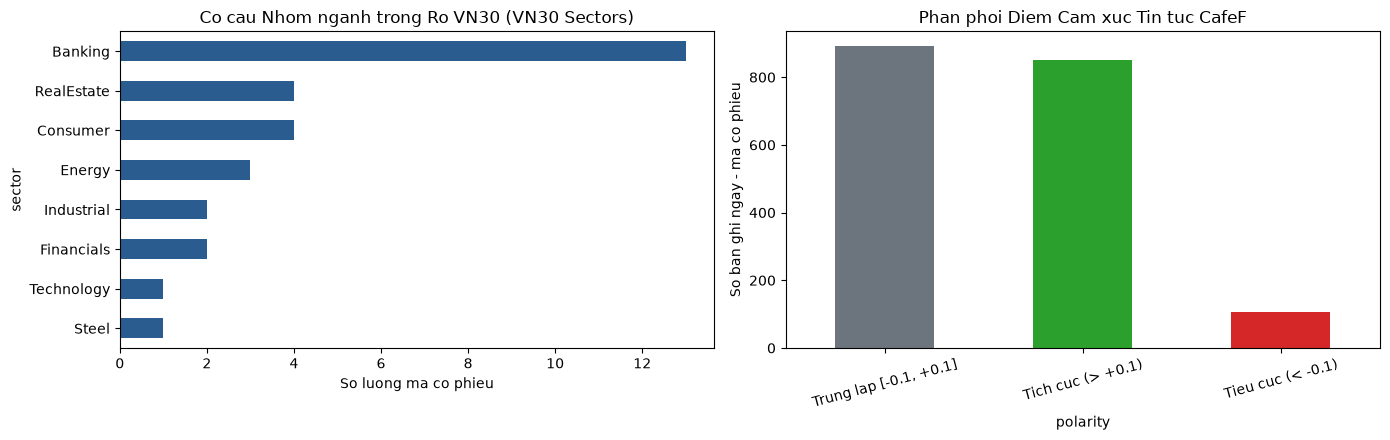

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Bieu do 1: Phan bo so luong phien giao dich theo nhom nganh
sector_counts = df_prices[df_prices['ticker'] != 'VNINDEX'].groupby('sector')['ticker'].nunique().sort_values()
sector_counts.plot(kind='barh', ax=axes[0], color='#2b5c8f')
axes[0].set_title('Co cau Nhom nganh trong Ro VN30 (VN30 Sectors)')
axes[0].set_xlabel('So luong ma co phieu')

# Bieu do 2: Phan phoi diem cam xuc tin tuc CafeF
df_news['polarity'] = df_news['sentiment_score'].apply(
    lambda s: 'Tich cuc (> +0.1)' if s > 0.1 else ('Tieu cuc (< -0.1)' if s < -0.1 else 'Trung lap [-0.1, +0.1]')
)
df_news['polarity'].value_counts().plot(kind='bar', ax=axes[1], color=['#6c757d', '#2ca02c', '#d62728'])
axes[1].set_title('Phan phoi Diem Cam xuc Tin tuc CafeF')
axes[1].set_ylabel('So ban ghi ngay - ma co phieu')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [8]:
# Kiem tra Definition of Done (Data Contracts)
for name, cols in [
    ('prices.parquet', ['date','ticker','open','high','low','close','volume','sector']),
    ('news_sentiment.parquet', ['date','ticker','news_count','sentiment_score','sample_headline']),
    ('macro.parquet', ['date','vnindex_close','vnindex_return_1d','vnindex_volatility_20d','usd_vnd_rate','sbv_policy_rate'])
]:
    df_check = pd.read_parquet(DATA_RAW_DIR / name)
    assert all(c in df_check.columns for c in cols), f'Thieu cot trong {name}'
    print(f'XAC NHAN HOP LE: {name:<23} | Kich thuoc: {str(df_check.shape):<14} | Null: {df_check.isnull().sum().sum()}')

XAC NHAN HOP LE: prices.parquet          | Kich thuoc: (54681, 8)     | Null: 0
XAC NHAN HOP LE: news_sentiment.parquet  | Kich thuoc: (1847, 5)      | Null: 0
XAC NHAN HOP LE: macro.parquet           | Kich thuoc: (1751, 6)      | Null: 0
